# Full EMG preprocessing, step by step

The analysis of [`emg-full.workflow.yaml`](emg-full.workflow.yaml), run one step
at a time in a notebook instead of with `m3resp run`.

Every call lists all the settings the function takes. Settings the workflow file
sets have its values; the others are at their defaults.

## 1. Import the required libraries

In [1]:
from pathlib import Path

from m3resp import M3Session
from m3resp.visualization import plot_session_overview
from m3resp.workflows.steps import emg, ventilator

## 2. Load the EMG and ventilator data

In [2]:
data_dir = Path("../../tests/data")

session = M3Session()
emg.load(
    session,
    file_path=data_dir / "emg_data_synth_quiet_breathing.Poly5",
    loader_options=None,  # extra settings for M3Session.load_emg
)
vent_data = ventilator.load(
    session,
    file_path=data_dir / "vent_data_synth_quiet_breathing.Poly5",
    source=None,  # which device's file this is; decides its clock
    name=None,  # name for this recording, when loading several
)
vent_signals = ventilator.channels(
    vent_data["ventilator_raw"],
    channels=("airway_pressure", "flow", "volume"),
    airway_pressure_channel=0,  # None: found by channel label
    flow_channel=1,
    volume_channel=2,
    fs=None,  # None: from the recording
)["ventilator_signals"]

Reading file  ..\..\tests\data\emg_data_synth_quiet_breathing.Poly5
	 Number of samples:  860160 
	 Number of channels:  2 
	 Sample rate: 2048 Hz
Done reading data.
Reading file  ..\..\tests\data\vent_data_synth_quiet_breathing.Poly5
	 Number of samples:  42000 
	 Number of channels:  3 
	 Sample rate: 100 Hz
Done reading data.


## 3. Preprocess the EMG and remove the ECG

Channel 1 (`EMGdi`) is the diaphragm EMG. Channel 0 (`ECG`) is a separate ECG
channel, used to find the ECG peaks. The envelope is computed after ECG gating,
from the gated signal.

In [3]:
# Filter
emg_filtered = emg.preprocess(
    session,
    channel=1,  # None: chosen from the channel labels
    high_pass_hz=20.0,
    low_pass_hz=None,  # None: 500 Hz, or 95 % of Nyquist if lower
    notch_base_frequency=None,  # e.g. 50 for mains hum; None: no notch filter
    notch_max_frequency=None,  # None: Nyquist
    notch_quality_factor=30.0,
    notch_before_bandpass=False,
    variant=None,  # store under a named variant instead of the default
)["processed_emg"]

In [4]:
# ECG removal: find the ECG peaks in the ECG channel, then gate them out
ecg_peak_indices = emg.ecg_detect_peaks(
    session,
    emg_filtered,
    ecg_channel=0,  # raw channel with the ECG; overrides source
    source="raw_channel",  # key of emg_filtered to detect the ECG in
    peak_fraction=0.4,
    peak_width_seconds=None,  # None: the detector's choice
    peak_distance_seconds=0.33,
    bandpass_filter=True,
)["ecg_peak_indices"]
emg_gated = emg.ecg_gating(
    session,
    emg_filtered,
    ecg_peak_indices,
    source=None,  # None: the ECG-cleaned trace if present, else filtered
    gate_width_seconds=None,  # set this or gate_width_samples, not both
    gate_width_samples=None,  # None: 205 samples
    fill_method=1,  # 0 zeros, 1 interpolation, 2 neighbour mean, 3 running RMS
)["processed_emg_after_ecg"]
len(ecg_peak_indices)

449

In [5]:
# Envelope
emg_processed = emg.envelope(
    session,
    emg_gated,
    window_seconds=0.25,
    method="rms",  # "rms", "arv" or "median"
    source=None,  # None: the ECG-cleaned trace if present, else filtered
)["processed_emg_with_envelope"]

## 4. Find the EMG breaths

The baseline comes first: a breath is a rise above the local quiet level, and
the detection threshold is taken from the envelope above that level.
`min_breath_width_seconds` is 0.5 s because the envelope bursts in this
recording are shorter than 1 s.

In [6]:
baseline = emg.moving_baseline(
    session,
    emg_processed,
    window_seconds=7.5,
    step_seconds=0.2,
    percentile=33.0,
)["baseline"]

emg_breaths = emg.detect_breaths(
    session,
    baseline=baseline,
    variant=None,  # detect in a named preprocessing variant
    min_breath_width_seconds=0.5,
    distance_seconds=0.5,  # minimum time between breath peaks
    threshold=0,
    prominence_factor=0.5,
)["emg_breath_events"]
peak_indices = emg.peak_indices(emg_breaths, emg_processed)["peak_indices"]
len(emg_breaths)

153

In [7]:
# Start and end of each breath: where the envelope crosses the baseline
onoff = emg.onoffpeak_baseline_crossing(session, emg_processed, baseline, peak_indices)
start_indices = onoff["start_indices"]
end_indices = onoff["end_indices"]

## 5. Calculate the EMG breath features

In [8]:
time_to_peak = emg.time_to_peak(emg_processed, start_indices, end_indices)[
    "time_to_peak"
]
pseudo_slope = emg.pseudo_slope(emg_processed, start_indices, end_indices)[
    "pseudo_slope"
]
amplitude = emg.amplitude(emg_processed, peak_indices, baseline)["amplitude"]
time_product = emg.time_product(emg_processed, start_indices, end_indices, baseline)[
    "time_product"
]
area_under_baseline = emg.area_under_baseline(
    emg_processed,
    peak_indices,
    start_indices,
    end_indices,
    baseline,
    window_seconds=5.0,  # window around each peak
)["area_under_baseline"]
respiratory_rate = emg.respiratory_rate(peak_indices, emg_processed)["respiratory_rate"]
respiratory_rate

(21.94285784256562,
 array([22.24072398, 22.38659136, 21.55033322, 22.36214741, 21.42632956,
        24.5416417 , 19.77470229, 23.99531342, 20.93356048, 22.37843744,
        22.59654285, 20.83064926, 21.86087885, 21.70257859, 23.68542791,
        21.29636049, 11.32325839, 20.25383221, 22.78509179, 22.16450216,
        22.55092678, 21.34815844, 24.0705191 , 20.04240744, 21.98211091,
        21.68725732, 24.23190692, 19.25113583, 23.05440901, 21.60717426,
        22.81046965, 22.44383562, 22.63400258, 20.70080863, 22.18851571,
        22.01755958, 21.90764842, 21.53900088, 24.66479326, 22.22463375,
        20.51419032, 21.93110833, 21.12792297, 24.17469998, 21.05912596,
        22.79777365, 20.67990576, 21.94677621, 25.14426028, 19.72075108,
        23.63986149, 20.67642605, 21.60717426, 22.28105168, 22.8189415 ,
        21.77179305, 21.28898129, 23.83705141, 20.562249  , 22.08483106,
        23.12817617, 21.33703768, 22.06500269, 21.24114088, 21.97817922,
        24.05638215, 21.1862069

## 6. Find the ventilator breaths and occlusion manoeuvres (Pocc)

In [9]:
vent_breath_indices = ventilator.detect_breaths(
    vent_signals,
    breath_width_seconds=0.25,
)["ventilator_breath_indices"]
pocc_indices = ventilator.find_occluded_breaths(
    vent_signals,
    peep=None,  # None: estimated from the end-expiratory pressure
)["pocc_indices"]
vent_respiratory_rate = ventilator.respiratory_rate(vent_breath_indices, vent_signals)[
    "ventilator_respiratory_rate"
]
vent_respiratory_rate, len(pocc_indices)

((21.978021978021978,
  array([21.97802198, 21.97802198, 21.97802198, 22.05882353, 21.97802198,
         21.97802198, 22.05882353, 21.97802198, 21.97802198, 22.05882353,
         21.97802198, 21.97802198, 21.97802198, 22.05882353, 21.97802198,
         21.97802198, 22.05882353, 21.97802198, 21.97802198, 21.97802198,
         22.05882353, 21.97802198, 21.97802198, 21.97802198, 22.05882353,
         21.97802198, 21.97802198, 22.05882353, 21.97802198, 21.97802198,
         22.05882353, 21.89781022, 22.05882353, 21.97802198, 21.97802198,
         21.97802198, 22.05882353, 22.05882353, 21.89781022, 22.05882353,
         21.97802198, 21.97802198, 22.05882353, 21.97802198, 21.97802198,
         21.97802198, 22.05882353, 21.97802198, 21.97802198, 22.05882353,
         21.97802198, 21.97802198, 21.97802198, 22.05882353, 21.97802198,
         21.97802198, 21.97802198, 22.05882353, 21.97802198, 21.97802198,
         22.05882353, 21.89781022, 22.05882353, 21.97802198, 21.97802198,
         22.0588

In [10]:
# Start, end and pressure-time product of each occlusion
pocc = ventilator.pocc_intervals(
    session,
    vent_signals,
    pocc_indices,
    baseline_window_seconds=7.5,
    baseline_step_seconds=0.2,
    baseline_percentile=33.0,
)
pocc_time_products = ventilator.pocc_time_product(
    session,
    vent_signals,
    pocc["pocc_start_indices"],
    pocc["pocc_end_indices"],
    pocc["pressure_baseline"],
    pocc_indices=pocc_indices,
    include_aub=True,  # add the area under the baseline
    aub_window_seconds=5.0,
)["pocc_time_products"]

# Store the ventilator breaths in the session
ventilator.normalize_breaths(
    vent_breath_indices,
    vent_signals,
    session,
    breath_width_seconds=0.5,
)
pocc_time_products

array([0.58305114, 0.39518907, 0.51653918, 0.42369046])

## 7. Test the quality

Each check stores one quality flag per breath (or one for the recording) in
`session.quality`.

In [11]:
snr = emg.snr_pseudo(
    session,
    emg_processed,
    peak_indices,
    baseline,
    minimum_snr=None,  # None: measure only, no pass/fail flags
)["snr_pseudo"]
percentage_under_baseline = emg.percentage_under_baseline(
    session,
    emg_processed,
    peak_indices,
    start_indices,
    end_indices,
    baseline,
    aub_window_seconds=None,  # None: each breath's own start-end window
    aub_threshold=40.0,  # maximum percentage under the baseline
)["percentage_under_baseline"]
local_high_aub = emg.detect_local_high_aub(
    session,
    area_under_baseline,
    peak_indices,
    threshold_percentile=75.0,
    threshold_factor=4.0,
)["detect_local_high_aub"]
extreme_time_products = emg.detect_extreme_time_products(
    session,
    time_product,
    peak_indices,
    upper_percentile=95.0,
    upper_factor=10.0,
    lower_percentile=5.0,
    lower_factor=0.1,
)["detect_extreme_time_products"]

In [12]:
non_consecutive_manoeuvres = ventilator.detect_non_consecutive_manoeuvres(
    session, vent_breath_indices, pocc_indices
)["detect_non_consecutive_manoeuvres"]
bell_curve_error = emg.evaluate_bell_curve_error(
    session, peak_indices, start_indices, end_indices, emg_processed, time_product
)["evaluate_bell_curve_error"]
event_timing = emg.evaluate_event_timing(
    session, peak_indices, emg_processed, vent_breath_indices, vent_signals
)["evaluate_event_timing"]
respiratory_rates_agree = emg.evaluate_respiratory_rates(
    session,
    peak_indices,
    emg_processed,
    vent_respiratory_rate,
    minimum_fraction=0.1,  # minimum fraction of expected EMG breaths found
)["evaluate_respiratory_rates"]
pocc_quality = ventilator.pocc_quality(
    session,
    vent_signals,
    pocc_indices,
    pocc["pocc_end_indices"],
    pocc_time_products,
    dp_up_10_threshold=0.0,
    dp_up_90_threshold=2.0,
    dp_up_90_norm_threshold=0.8,
)["pocc_quality"]
interpeak_distance = emg.interpeak_dist(
    session,
    ecg_peak_indices,
    peak_indices,
    emg_processed,
    threshold=1.1,  # maximum EMG/ECG interpeak distance ratio
)["interpeak_dist"]

## 8. Results

In [13]:
{name: len(events) for name, events in session.events.items()}

{'ecg_peaks': 449,
 'emg_breaths': 153,
 'pocc_breaths': 4,
 'ventilator_breaths': 154}

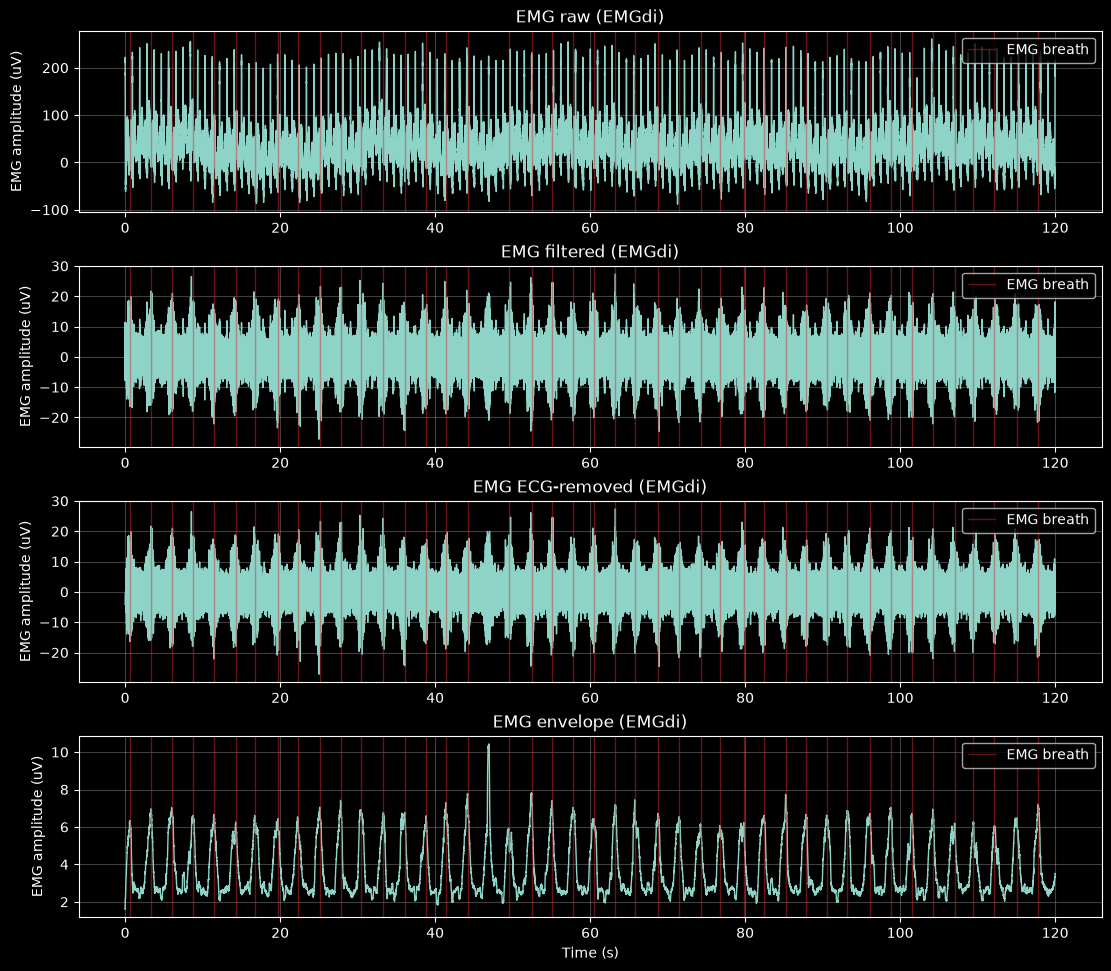

In [14]:
fig = plot_session_overview(
    session,
    max_seconds=120.0,  # None: the whole recording
    emg_channel=1,  # the channel the EMG processing used
    eit_waveform="global_impedance_(raw)",  # not used: no EIT here
    backend="matplotlib",  # or "plotly"
    max_points=5000,
)